# Задание 4.15

В прямоугольной области, заданной ограничениями $|x|\le20$ и $|y|\le8$, случайным образом выбираются две точки: $(x_1,y_1)$ и $(x_2,y_2)$. Пусть $A$ и $B$ — события, состоящие в том, что: $A$ — расстояние между выбранными точками меньше 11; $B$ — модуль разности $|x_1-x_2|$ меньше 14. Найдите приближённо, методом Монте-Карло: 1) вероятность $\mathbb P(A)$; 2) условную вероятность $\mathbb P(A\mid B)$. *Указание:* получите в заданной прямоугольной области 100000 пар точек и, используя все эти точки, найдите ответы, округляя их до одного знака после запятой.

**Ответ:** 1) $\mathbb P(A)=0{,}37$; 2) $\mathbb P(A\mid B)=0{,}64$.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Метод Монте-Карло.** Вероятность события оценивается его относительной частотой в $N$ независимых опытах: $\mathbb P(A)\approx\hat p(A)=\dfrac{N(A)}{N}$. Погрешность порядка $\sqrt{p(1-p)/N}\approx0{,}0015$ при $N=10^5$. Условная вероятность оценивается частотой внутри подвыборки, где произошло $B$:

$$
\mathbb P(A\mid B)=\frac{\mathbb P(AB)}{\mathbb P(B)}\approx\frac{N(AB)}{N(B)} .
$$

**Модель.** Точки равномерны в прямоугольнике $[-20,20]\times[-8,8]$; $\Omega$ — пары точек, $\mu(\Omega)=(40\cdot16)^2$.

**Контроль через точный расчёт.** Разности $u=x_1-x_2$ и $v=y_1-y_2$ независимы и имеют треугольные плотности

$$
f(u)=\frac{40-|u|}{40^2},\ |u|\le40;\qquad g(v)=\frac{16-|v|}{16^2},\ |v|\le16 .
$$

Поэтому

$$
\mathbb P(A)=\iint_{u^2+v^2<121}f(u)\,g(v)\,du\,dv,\qquad
\mathbb P(B)=\mathbb P(|u|<14)=1-\Big(1-\frac{14}{40}\Big)^2=0{,}5775 .
$$

**Важное наблюдение:** $A\subset B$. Если расстояние меньше 11, то $|x_1-x_2|<11<14$. Значит, $\mathbb P(AB)=\mathbb P(A)$ и $\mathbb P(A\mid B)=\mathbb P(A)/\mathbb P(B)$. Двойной интеграл считаем численно (`scipy.integrate.dblquad`).

Численное интегрирование: P(A) = 0.36920,  P(B) = 0.57750,  P(A|B) = P(A)/P(B) = 0.63931
Монте-Карло (N = 100000): P(A) ≈ 0.3671 ≈ 0.37,  P(A|B) ≈ 0.6358 ≈ 0.64
Проверка вложенности A ⊂ B: событий A вне B — 0


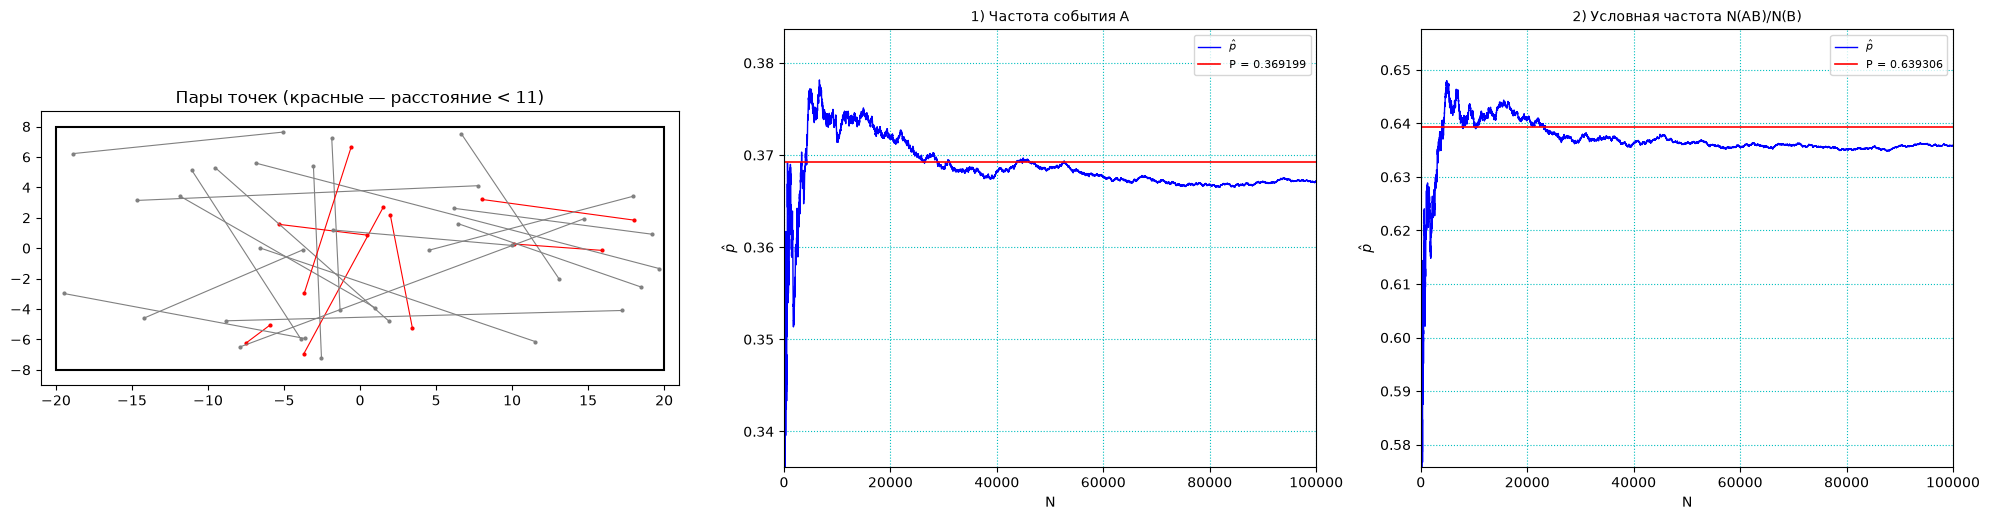

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import dblquad

rng = np.random.default_rng(1)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


# ---------- Контрольный расчёт через плотности разностей ----------
a, b, d, dx = 20, 8, 11, 14
f = lambda u: (2*a - abs(u)) / (2*a)**2                 # плотность u = x1 - x2
g = lambda v: (2*b - abs(v)) / (2*b)**2                 # плотность v = y1 - y2
PA_ref, _ = dblquad(lambda v, u: f(u)*g(v), -d, d,
                    lambda u: -min(2*b, np.sqrt(d**2 - u**2)), lambda u: min(2*b, np.sqrt(d**2 - u**2)))
PB_ref = 1 - (1 - dx/(2*a))**2
print(f"Численное интегрирование: P(A) = {PA_ref:.5f},  P(B) = {PB_ref:.5f},  P(A|B) = P(A)/P(B) = {PA_ref/PB_ref:.5f}")

# ---------- Метод Монте-Карло: 100 000 пар точек ----------
N = 100_000
x1, x2 = rng.uniform(-a, a, (2, N))
y1, y2 = rng.uniform(-b, b, (2, N))
A = np.hypot(x1 - x2, y1 - y2) < d          # расстояние между точками меньше 11
B = np.abs(x1 - x2) < dx                    # |x1 - x2| < 14
PA_mc = A.mean()
PAB_mc = (A & B).sum() / B.sum()            # условная частота N(AB)/N(B)
print(f"Монте-Карло (N = {N}): P(A) ≈ {PA_mc:.4f} ≈ {PA_mc:.2f},  P(A|B) ≈ {PAB_mc:.4f} ≈ {PAB_mc:.2f}")
print(f"Проверка вложенности A ⊂ B: событий A вне B — {np.sum(A & ~B)}")

fig, axes = plt.subplots(1, 3, figsize=(20, 5.3), gridspec_kw={"width_ratios": [1.2, 1, 1]})
for i in range(25):                         # примеры пар точек
    axes[0].plot([x1[i], x2[i]], [y1[i], y2[i]], "-o", ms=2, lw=0.8, color="red" if A[i] else "gray")
axes[0].add_patch(plt.Rectangle((-a, -b), 2*a, 2*b, fill=False, lw=1.5))
axes[0].set_xlim(-a - 1, a + 1); axes[0].set_ylim(-b - 1, b + 1); axes[0].set_aspect("equal")
axes[0].set_title("Пары точек (красные — расстояние < 11)")
plot_freq(axes[1], A, PA_ref, "1) Частота события A")
plot_freq(axes[2], A, PA_ref/PB_ref, "2) Условная частота N(AB)/N(B)", cond=B)
fig.tight_layout()
plt.show()